# EEC174AY Project A1: PreLab
You are NOT allowed to import any other libraries in this notebook otherwise points will be deducted. If you need to please confirm with the TA. ''' TODO ''' Indicates where your solution code should go. Please ensure code is readable easily.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Part 1: Visualizing Ground Truth Bounding Boxes

The code below is provided to load `imgs/cats.jpg` and display it using [opencv](https://docs.opencv.org/4.x/).

You must add code to display the bounding boxes, which are given as `gt_boxes` in green color. These represent the ground truth bounding box coordinates in `[x, y, w, h]` format.

Please use `cv2.rectange()` to achieve this. Click [here](https://docs.opencv.org/4.x/dc/da5/tutorial_py_drawing_functions.html) to see hint.

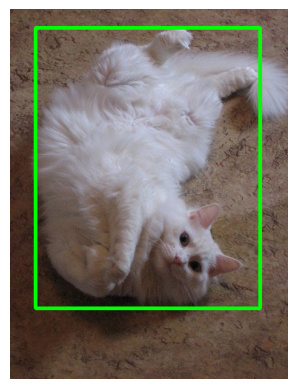

In [5]:
# Load the image
image_path = "imgs/cat.jpg"
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Ground truth bounding box [x, y, w, h]
gt_box = [34, 25, 303, 379]

# Use gt_boxes and display the bounding boxes in green color
# Unpack [x, y, w, h] and convert to the two corners cv2.rectangle needs
x, y, w, h = gt_box
image_gt = image_rgb.copy()  # draw on a copy so image_rgb stays clean for Part 3
cv2.rectangle(image_gt, (x, y), (x + w, y + h), (0, 255, 0), 3)

# Display the image with bounding boxes using matplotlib
plt.imshow(image_gt)
plt.axis('off')  # Hide axes
plt.show()


## Part 2: Implementing the IoU Function

Complete the `compute_iou()` function. This function should accept two bounding boxes and return the IoU value between them. Ensure that the function can handle edge cases (e.g., no overlap between the boxes).

(Hint: See Lecture W5L1_Object Detection Slide 11)

In [6]:
def compute_iou(boxA, boxB):
    # Convert [x, y, w, h] to corners [x1, y1, x2, y2]
    ax1, ay1, ax2, ay2 = boxA[0], boxA[1], boxA[0] + boxA[2], boxA[1] + boxA[3]
    bx1, by1, bx2, by2 = boxB[0], boxB[1], boxB[0] + boxB[2], boxB[1] + boxB[3]

    # Intersection rectangle: furthest-in left/top edges and closest-in right/bottom edges
    inter_x1 = max(ax1, bx1)
    inter_y1 = max(ay1, by1)
    inter_x2 = min(ax2, bx2)
    inter_y2 = min(ay2, by2)

    # Clamp to 0 so boxes that don't overlap give 0 instead of a negative area
    inter_w = max(0, inter_x2 - inter_x1)
    inter_h = max(0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h

    # Union = both areas minus the overlap (otherwise the overlap is counted twice)
    areaA = boxA[2] * boxA[3]
    areaB = boxB[2] * boxB[3]
    union_area = areaA + areaB - inter_area

    return inter_area / union_area if union_area > 0 else 0.0


## Part 3: Visualizing Predicted Bounding Boxes and Computing IoUs

Four sets of predicted bounding boxes have been provided in `predictions`. The ground truth bounding boxes are in `gt_boxes`

For each set of predicted bounding boxes:
1. Draw the predicted boxes on a copy of the original image in red.
2. Draw the ground truth boxes on the same image in green.
3. Compute the IoU for predictions and ground truth.
4. Display the image with both the predicted and ground truth boxes. Use the title of the plot to display the maximum IoU value for each prediction.

You should have 4 images, each with a GT and prediction (1,2,3 or 4) bounbding box plotted (GT in green,. pred in red), and the IoU be the title of the images.

In [ ]:
# Predicted bounding boxes [x, y, w, h]
predictions = [
    [38, 28, 282, 371],  # Pred 1
    [50, 40, 240, 340],  # Pred 2
    [10, 10, 240, 340],  # Pred 3
    [10, 420, 80, 70]    # Pred 4
]

# For each predicted box, visualize it on the image individually (with GT)
#   and compute its IoU with the ground truth.
# One row of 4 plots, one per prediction
fig, axes = plt.subplots(1, len(predictions), figsize=(20, 5))
fig.suptitle("PreLab Output", fontsize=16)

gx, gy, gw, gh = gt_box
for i, pred in enumerate(predictions):
    # Fresh copy each time so every plot shows only GT + this one prediction
    img = image_rgb.copy()

    # Ground truth in green, prediction in red ([x, y, w, h] -> corners)
    px, py, pw, ph = pred
    cv2.rectangle(img, (gx, gy), (gx + gw, gy + gh), (0, 255, 0), 3)
    cv2.rectangle(img, (px, py), (px + pw, py + ph), (255, 0, 0), 3)

    # IoU between this prediction and the ground truth
    iou = compute_iou(pred, gt_box)

    axes[i].imshow(img)
    axes[i].set_title("Pred {} - IoU: {:.2f}".format(i + 1, iou))
    axes[i].axis('off')

plt.show()
